# 🚗 Flood Water Level & Vehicle Submersion Classifier
### Capstone Project: Real-time Flood Segmentation & Road Passability Estimation
**Institution:** Ramdeobaba University, Nagpur (Dept. of Electronics Engineering)
**Goal:** Train a lightweight Deep Learning model on the `flooded_cars` dataset (5 submersion levels: Level 0 to Level 4) to estimate physical flood depth and road passability without heavy foundation models.

---
### 📊 Dataset Level Definitions & Passability Mapping:
| Level | Physical Water Line on Vehicle | Estimated Water Depth | Passability Status | Action / Advisory |
| :---: | :--- | :---: | :---: | :--- |
| **Level 0** | Dry / Wheels fully on ground | **0 – 10 cm** | 🟢 **Passable** | Safe for all vehicles. Normal conditions. |
| **Level 1** | Water touching lower tire / tread | **10 – 25 cm** | 🟢 **Passable (Caution)** | Low risk; safe for most vehicles. |
| **Level 2** | Water at wheel center / door sill | **25 – 40 cm** | 🟡 **Partially Flooded** | Caution; SUVs / Emergency trucks only. Sedans avoid. |
| **Level 3** | Water at top of tire / wheel arch | **40 – 60 cm** | 🔴 **Severely Flooded** | Impassable; danger of engine stalling / air intake flood. Reroute! |
| **Level 4** | Submerged past hood / windows | **> 60 cm** | 🔴 **Severely Flooded** | Disaster zone; vehicles submerged. Completely impassable. |

In [13]:
# 1. Environment & GPU Check
import torch
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


## 2. Upload and Extract Dataset
Upload `flooded_cars.zip` from your computer using the file browser on the left, or mount Google Drive.

In [14]:
import zipfile
import shutil
import os

# Path where flooded_cars.zip is uploaded in Colab
zip_path = 'flooded_cars.zip'

# (Optional) If you put it in Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')
# zip_path = '/content/drive/MyDrive/flooded_cars.zip'

extract_dir = 'flooded_cars_data'
if os.path.exists(zip_path):
    file_size = os.path.getsize(zip_path) / (1024 * 1024) # Size in MB
    print(f"Found '{zip_path}' ({file_size:.2f} MB)")

    if file_size == 0:
        print("Error: The uploaded file is empty (0 MB). Please re-upload the file fully before proceeding.")
    else:
        print('Extracting dataset...')
        try:
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(extract_dir)
            print('Extraction complete!')
        except zipfile.BadZipFile:
            print("\n[ERROR] BadZipFile: The file is not a valid zip archive.")
            print("This usually means the upload was interrupted or the file is corrupted.")
            print("Please delete 'flooded_cars.zip' from the sidebar, wait for the upload to finish completely, and try again.")
else:
    print(f'Please upload {zip_path} into Colab files (left sidebar)!')

Found 'flooded_cars.zip' (167.62 MB)
Extracting dataset...
Extraction complete!


In [15]:
# Detect folder containing Level0, Level1, Level2, Level3, Level4
import glob

dataset_root = None
for root, dirs, files in os.walk(extract_dir):
    if any('Level0' in d for d in dirs):
        dataset_root = root
        break

print(f"Found dataset root: {dataset_root}")
levels = sorted([d for d in os.listdir(dataset_root) if os.path.isdir(os.path.join(dataset_root, d)) and 'Level' in d])
for lvl in levels:
    count = len(glob.glob(os.path.join(dataset_root, lvl, '*.*')))
    print(f"{lvl}: {count} images")

Found dataset root: flooded_cars_data/upscaled_images
Level0: 1212 images
Level1: 706 images
Level2: 1116 images
Level3: 445 images
Level4: 300 images


## 3. Data Loaders & Data Augmentations
Split into 70% Train, 15% Validation, 15% Test.

In [16]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Dataset
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32

# Enhanced Data Augmentation with RandAugment and Random Erasing
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandAugment(num_ops=2, magnitude=9), # Automatically applies strong, diverse augmentations
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.2), value='random') # Simulates obstructions
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder(dataset_root)
print("Class to index mapping:", full_dataset.class_to_idx)

# Keep the exact same splits for fair comparison
n_total = len(full_dataset)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

torch.manual_seed(42)
train_sub, val_sub, test_sub = random_split(full_dataset, [n_train, n_val, n_test])

class CustomTransformDataset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __getitem__(self, idx):
        img, label = self.subset[idx]
        return self.transform(img), label
    def __len__(self):
        return len(self.subset)

train_ds = CustomTransformDataset(train_sub, train_transforms)
val_ds = CustomTransformDataset(val_sub, val_transforms)
test_ds = CustomTransformDataset(test_sub, val_transforms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)} | Test samples: {len(test_ds)}")

Class to index mapping: {'Level0': 0, 'Level1': 1, 'Level2': 2, 'Level3': 3, 'Level4': 4}
Train samples: 2645 | Val samples: 566 | Test samples: 568


## 4. Build Model (MobileNetV3-Small)
Aligned with your project's lightweight edge focus:
- Only **1.5 Million parameters**
- Inference latency: **< 15 ms on CPU** (> 60 FPS)
- Pretrained on ImageNet for rapid convergence

In [17]:
import torch.nn as nn
from torchvision import models

def get_flood_level_model(num_classes=5):
    model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model

model = get_flood_level_model(num_classes=len(full_dataset.classes)).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model initialized with {n_params / 1e6:.2f}M trainable parameters.")

Model initialized with 1.52M trainable parameters.


## 5. Training Loop
Trains in ~3 to 5 minutes on Colab GPU.

In [22]:
import torch.optim as optim
import time

# Slightly lower learning rate + Label Smoothing to prevent overfitting
EPOCHS = 30
LEARNING_RATE = 1e-4

# label_smoothing=0.1 forces the model to generalize better and not become overconfident
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2) # Increased weight decay
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_val_acc = 0.0
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print('Starting training on GPU with enhanced generalizations...')
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    # Training Phase
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    scheduler.step()
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = train_correct / train_total

    # Validation Phase
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total

    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)

    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc*100:.2f}%")

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_acc': best_val_acc,
            'classes': full_dataset.classes,
            'class_to_idx': full_dataset.class_to_idx,
            'arch': 'mobilenet_v3_small'
        }, 'best_flood_level_model.pth')
        print(f"  --> [SAVED] New best model saved! (Val Acc: {best_val_acc*100:.2f}%)")

elapsed_mins = (time.time() - t0) / 60.0
print(f"Training finished in {elapsed_mins:.1f} mins. Peak Val Acc: {best_val_acc*100:.2f}%")

Starting training on GPU with enhanced generalizations...
Epoch [01/30] Train Loss: 0.7117 Acc: 85.26% | Val Loss: 0.8356 Acc: 76.15%
  --> [SAVED] New best model saved! (Val Acc: 76.15%)
Epoch [02/30] Train Loss: 0.6999 Acc: 85.22% | Val Loss: 0.8277 Acc: 76.33%
  --> [SAVED] New best model saved! (Val Acc: 76.33%)
Epoch [03/30] Train Loss: 0.6650 Acc: 87.94% | Val Loss: 0.8402 Acc: 75.44%
Epoch [04/30] Train Loss: 0.6411 Acc: 89.60% | Val Loss: 0.8331 Acc: 78.62%
  --> [SAVED] New best model saved! (Val Acc: 78.62%)
Epoch [05/30] Train Loss: 0.6238 Acc: 89.79% | Val Loss: 0.8085 Acc: 79.15%
  --> [SAVED] New best model saved! (Val Acc: 79.15%)
Epoch [06/30] Train Loss: 0.6106 Acc: 90.66% | Val Loss: 0.8086 Acc: 80.21%
  --> [SAVED] New best model saved! (Val Acc: 80.21%)
Epoch [07/30] Train Loss: 0.5901 Acc: 91.38% | Val Loss: 0.8223 Acc: 77.74%
Epoch [08/30] Train Loss: 0.5867 Acc: 91.80% | Val Loss: 0.8035 Acc: 79.15%
Epoch [09/30] Train Loss: 0.5749 Acc: 92.93% | Val Loss: 0.8193 

## 6. Test Set Evaluation & Metrics
Evaluates Classification Report, Confusion Matrix, and Ordinal Level Error.


--- Classification Report ---
              precision    recall  f1-score   support

      Level0     0.8207    0.8779    0.8483       172
      Level1     0.6835    0.4779    0.5625       113
      Level2     0.7337    0.8438    0.7849       160
      Level3     0.7250    0.7532    0.7389        77
      Level4     0.8537    0.7609    0.8046        46

    accuracy                         0.7623       568
   macro avg     0.7633    0.7427    0.7478       568
weighted avg     0.7586    0.7623    0.7552       568

Mean Absolute Error across Levels: 0.269 levels


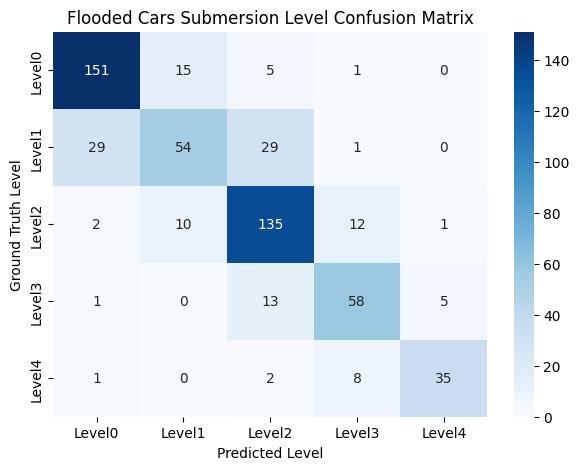

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error
import seaborn as sns

# Load best checkpoint
ckpt = torch.load('best_flood_level_model.pth', map_location=device)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

class_names = full_dataset.classes
print("\n--- Classification Report ---")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

mae = mean_absolute_error(all_targets, all_preds)
print(f"Mean Absolute Error across Levels: {mae:.3f} levels")

# Plot Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Flooded Cars Submersion Level Confusion Matrix')
plt.xlabel('Predicted Level')
plt.ylabel('Ground Truth Level')
plt.show()

## 7. Passability Inference Function
Maps predictions directly to passability status & depth ranges.

In [24]:
from PIL import Image

PASSABILITY_MAP = {
    0: {'status': 'Passable', 'depth_cm': '0 - 10 cm', 'color': '#10B981', 'risk': 'Low Risk (Dry / Minimal Water)'},
    1: {'status': 'Passable', 'depth_cm': '10 - 25 cm', 'color': '#10B981', 'risk': 'Safe for most vehicles'},
    2: {'status': 'Partially Flooded', 'depth_cm': '25 - 40 cm', 'color': '#F59E0B', 'risk': 'Caution: SUVs/Trucks only'},
    3: {'status': 'Severely Flooded', 'depth_cm': '40 - 60 cm', 'color': '#EF4444', 'risk': 'Unsafe: Engine flood hazard'},
    4: {'status': 'Severely Flooded', 'depth_cm': '> 60 cm', 'color': '#EF4444', 'risk': 'Extreme Hazard: Submerged'}
}

def predict_flood_passability(img_path_or_pil):
    model.eval()
    if isinstance(img_path_or_pil, str):
        pil_img = Image.open(img_path_or_pil).convert('RGB')
    else:
        pil_img = img_path_or_pil.convert('RGB')

    tensor = val_transforms(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        outputs = model(tensor)
        probs = torch.softmax(outputs, dim=1).squeeze().cpu().numpy()
        pred_idx = int(np.argmax(probs))

    level_name = class_names[pred_idx]
    confidence = float(probs[pred_idx])
    info = PASSABILITY_MAP[pred_idx]

    return {
        'predicted_level': level_name,
        'confidence': f"{confidence * 100:.1f}%",
        'passability_status': info['status'],
        'estimated_depth': info['depth_cm'],
        'driving_risk': info['risk'],
        'probabilities': {class_names[i]: f"{float(probs[i])*100:.1f}%" for i in range(len(class_names))}
    }

# Test on sample test image
sample_img, sample_lbl = test_sub[0]
res = predict_flood_passability(sample_img)
print('Sample Test Result:', res)

Sample Test Result: {'predicted_level': 'Level2', 'confidence': '96.6%', 'passability_status': 'Partially Flooded', 'estimated_depth': '25 - 40 cm', 'driving_risk': 'Caution: SUVs/Trucks only', 'probabilities': {'Level0': '0.5%', 'Level1': '1.5%', 'Level2': '96.6%', 'Level3': '1.2%', 'Level4': '0.2%'}}


## 8. Download Trained Weights
Download `best_flood_level_model.pth` and place it in your local `dl_project-main/weights/` folder.

In [25]:
from google.colab import files
files.download('best_flood_level_model.pth')
print('Download initiated!')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download initiated!
